In [21]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

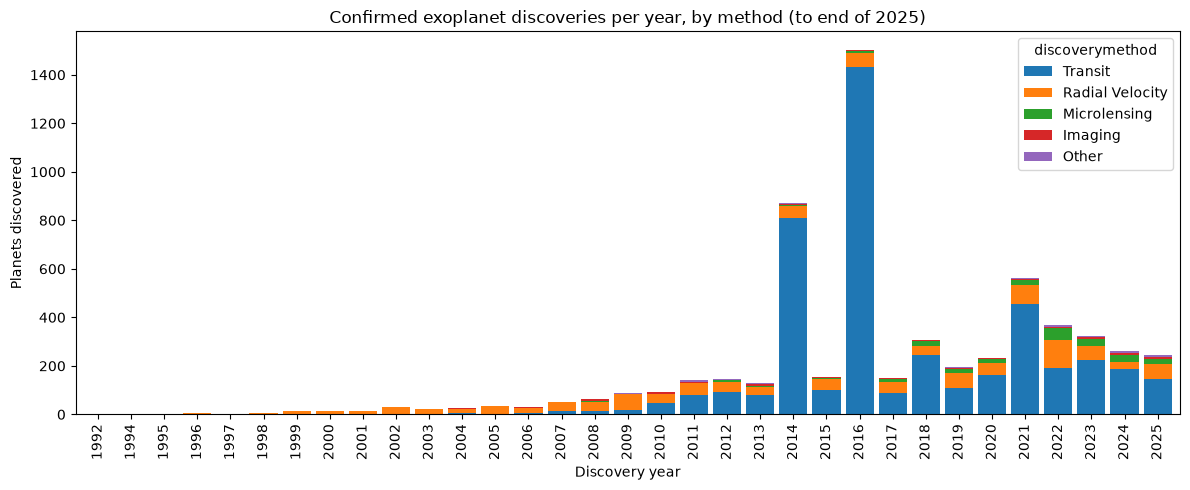

In [ ]:
# Discoveries by year per method
conn = sqlite3.connect("../data/exoplanets.db")
df = pd.read_sql("""
    SELECT disc_year, discoverymethod, COUNT(*) AS n
    FROM planets
    WHERE disc_year < 2026
    GROUP BY disc_year, discoverymethod
""", conn)

pivot = df.pivot(index="disc_year", columns="discoverymethod", values="n").fillna(0)

# keeping 4 biggest methods, rest are 'other'
top = pivot.sum().nlargest(4).index
pivot["Other"] = pivot.drop(columns=top).sum(axis=1)
pivot = pivot[list(top) + ["Other"]]

ax = pivot.plot(kind="bar", stacked=True, figsize=(12, 5), width=0.85)
ax.set_xlabel("Discovery year")
ax.set_ylabel("Planets discovered")
ax.set_title("Confirmed exoplanet discoveries per year, by method (to end of 2025)")
plt.tight_layout()
plt.show()


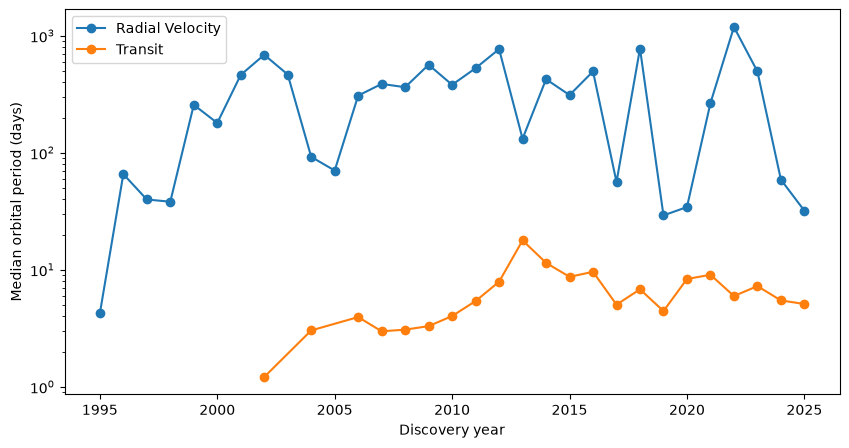

In [ ]:
# median orbital period against discovery year

df = pd.read_sql("SELECT * FROM planets WHERE disc_year < 2026", conn)
main = df[df["discoverymethod"].isin(["Transit", "Radial Velocity"])]

fig, ax = plt.subplots(figsize=(10,5))
for method, group in main.groupby("discoverymethod"):
    ax.plot(group.groupby("disc_year")["pl_orbper"].median(), marker="o", label=method)
ax.set_yscale("log")
ax.set_xlabel("Discovery year")
ax.set_ylabel("Median orbital period (days)")
ax.legend()
plt.show()

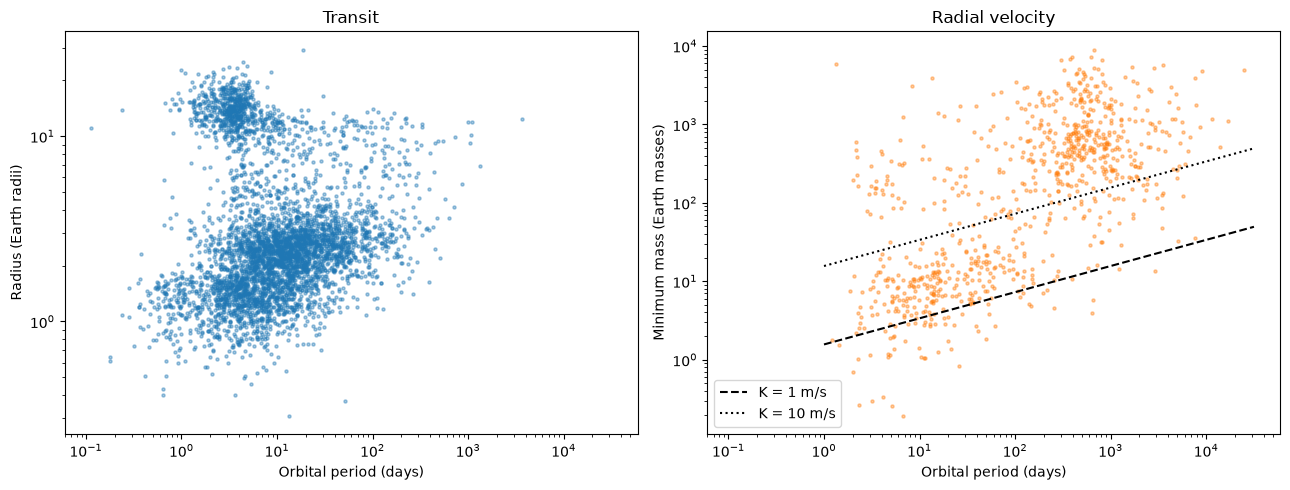

In [ ]:
# two panel transit and rv radius and mass against orbital period
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

transit = df[df["discoverymethod"] == "Transit"]
ax1.scatter(transit["pl_orbper"], transit["pl_rade_measured"], s=5, alpha=0.4)
ax1.set(xscale="log", yscale="log", xlabel="Orbital period (days)",
        ylabel="Radius (Earth radii)", title="Transit")

rv = df[(df["discoverymethod"] == "Radial Velocity") & df["mass_is_lower_limit"]]
ax2.scatter(rv["pl_orbper"], rv["pl_bmasse"], s=5, alpha=0.4, color="C1")
ax2.set(xscale="log", yscale="log", xlabel="Orbital period (days)",
        ylabel="Minimum mass (Earth masses)", title="Radial velocity")

M_JUP_IN_EARTH = 317.8
periods = np.logspace(0, 4.5, 100)  # days

for k_min, style in [(1, "--"), (10, ":")]:  # sensitivity in m/s
    m_min = (k_min / 28.4) * (periods / 365.25) ** (1 / 3) * M_JUP_IN_EARTH
    ax2.plot(periods, m_min, style, color="k", label=f"K = {k_min} m/s")

ax2.legend()
plt.tight_layout()
plt.savefig("../figures/detection_regions.png", dpi=150, bbox_inches="tight")
plt.show()